# 04 · MPC with constant fill probabilities against crossing

Same experiment as notebook 02 (200 orders of 500 shares, 20 steps of `dt` = 5, TWAP, same seeds), now with the
MPC policy of McAuliffe et al. (2026) using the constant fill probabilities measured in notebook 03.
Five questions:
1. what MPC does on one order, step by step;
2. what it saves against crossing, and where the saving comes from;
3. whether the deviation from the schedule is centred, and whether the fill probability it assumes is the one it obtains;
4. how cost and deviation trade off when the tubes change;
5. when the quadratic penalty starts to matter.

In [1]:
%reload_ext autoreload
%autoreload 2
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from mpc_execution.book import Side
from mpc_execution.simulator import Simulator, SimParams
from mpc_execution.schedule import twap
from mpc_execution.policies import Crossing, Traced
from mpc_execution.fills import collect_fill_samples, ConstantFill
from mpc_execution.mpc import MPC, MPCParams
from mpc_execution.experiment import run_order, run_many
from mpc_execution.metrics import summarize, deviation, fwap, swap

FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
Q, N, DT, N_ORDERS = 500, 20, 5.0, 200
params, schedule, k = SimParams(), twap(Q, N), np.arange(N + 1)
fill = ConstantFill.from_samples(collect_fill_samples(params, 5, 25, DT, 2000, seed=0))
mpc_params = MPCParams()
print(fill.pi.round(3))
print(mpc_params)

[0.606 0.115 0.037 0.018 0.008]
MPCParams(n_levels=3, gamma=0.02, xi=0.5, rho_up=25.0, rho_low=50.0, beta=None, kappa_frac=0.5)


### 1. A single order slowed down

**How it works.** One experiment executes a *parent order* (say, buy 500 shares) over n decision steps against a simulated
limit order book. At every step:

1. the book is photographed (`Simulator.snapshot`);
2. a *policy* receives the snapshot, the quantity executed so far and the schedule target for the end of
   the step, and returns child orders (`Policy.decide`);
3. market orders execute immediately, limit orders join the queue;
4. the simulated order flow runs for `dt` (`Simulator.step`); incoming market orders may fill our resting orders;
5. whatever is left of ours is cancelled, and the loop repeats.

Policies differ only in step 2. *Crossing* sends the scheduled slice as a market order: it never leaves the
schedule and pays half a spread per share. *MPC* solves a small quadratic program at every step: a share
posted at the touch earns half a spread instead of paying it, but fills only with probability pi. The QP posts
as much as the schedule tolerance allows and uses market orders only when the order has fallen too far
behind, or at the last step. How good that decision is depends on pi, which is where the fill-probability
models come in.

The tolerance is a tube around the schedule: by default the order may run up to `rho_up` = 25 shares ahead and
`rho_low` = 50 shares behind.

In [2]:
sim = Simulator(params, seed=0)
sim.step(50.0)
tr = Traced(MPC(fill, mpc_params))
r = run_order(sim, tr, Side.BUY, Q, schedule, DT)

rows = []
for step, (q, target, spread, orders) in enumerate(tr.log):
    rows.append({"q": q, "target": target, "gap": target - q, "spread": spread,
                 "market": sum(n for kind, n, _ in orders if kind == "market"),
                 "limits": [n for kind, n, _ in orders if kind == "limit"],
                 "filled": r.filled_path[step + 1] - r.filled_path[step]})
pd.DataFrame(rows).rename_axis("step")

,q,target,gap,spread,market,limits,filled
step,,,,,,,
0,0,25,25,1,0,[50],0
1,0,50,50,1,0,[75],75
2,75,75,0,1,0,[25],25
3,100,100,0,1,0,[25],25
4,125,125,0,1,0,[25],25
5,150,150,0,1,0,[25],25
6,175,175,0,1,0,[25],25
7,200,200,0,1,0,[25],25
8,225,225,0,1,0,[25],25


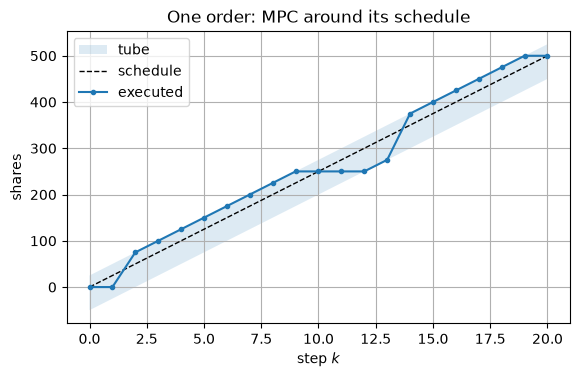

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.fill_between(k, schedule - mpc_params.rho_low, schedule + mpc_params.rho_up, alpha=0.15, label="tube")
ax.plot(k, schedule, "k--", lw=1, label="schedule")
ax.plot(k, r.filled_path, marker="o", ms=3, label="executed")
ax.set(xlabel=r"step $k$", ylabel="shares", title="One order: MPC around its schedule")
ax.grid()
ax.legend()
fig.savefig(FIG / "04_one_order.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the trace.** `gap` is what the schedule asks by the end of the step minus what is executed; `market` and
`limits` are the child orders sent; `filled` is what was executed during the step. All limit orders are at the touch:
the levels behind it are never used.
- Step 0: on schedule. MPC posts 50 at the best bid, twice the slice, and no market order. Nothing fills.
- Step 1: 25 behind. It posts 75, all 75 fill, and the order jumps to 25 ahead.
- Steps 2–8: one slice ahead. It posts 25 per step, each fills, and the order rides the upper edge of the tube.
- Steps 9–11: three steps without a fill. The order slides from +25 to −50; postings grow 25 → 50 → 75.
- Steps 12–13: the gap (75) exceeds `rho_low`, so 25 shares per step go to market. These 50 shares are the only
  ones in the order that pay the spread. At step 13 the 75 posted fill too, and the order is back at the upper edge.
- The order completes one step early; 450 of 500 shares were bought at the bid.

**The rule behind it.** In every step the total sent equals gap + `rho_up`: the upper tube is the binding constraint.
At these settings the QP reduces to "post gap + `rho_up` at the touch; send to market what exceeds `rho_low`".
The quadratic penalty is inactive (section 5 shows when it starts to matter).

### 2. Comparison

**Expectation.** Measure each share against the mid of the step in which it trades. A market order pays half a spread
(+0.5 bp when the spread is one tick); a limit order filled at the touch earns it (−0.5). If a fraction $f$ of the
shares is passive, the average is $(1-f)\,0.5 - f\,0.5 = 0.5 - f$.

The schedule shortfall, however, measures each share against the mid of the step in which the *schedule* placed it.
For crossing the two coincide. MPC trades earlier or later than scheduled, and not at random: a passive order fills
when the market comes to it and misses when the market moves away. So the shortfall should be worse than $0.5 - f$
by a *timing cost*, and the arrival slippage should improve less than the shortfall.

In [4]:
class Factory:
    """Builds a fresh policy per order and keeps them, to read n_fallbacks afterwards."""
    def __init__(self, make):
        self.make, self.made = make, []

    def __call__(self):
        self.made.append(self.make())
        return self.made[-1]

def run(policy_factory, n_orders=N_ORDERS):
    res = run_many(params, policy_factory, dt=DT, schedule=schedule, n_orders=n_orders, seed0=0)
    df = pd.DataFrame(map(summarize, res))
    df["passive_share"] = [sum(e.qty for e in r.executions if e.passive) / r.filled for r in res]
    df["rms_deviation"] = [np.sqrt(np.mean(deviation(r)[1:-1] ** 2)) for r in res]
    return res, df

In [5]:
%%time
res_x, df_x = run(Crossing)
f_mpc = Factory(lambda: MPC(fill, mpc_params))
res_m, df_m = run(f_mpc)
print("fallbacks:", sum(p.n_fallbacks for p in f_mpc.made))

fallbacks: 0
CPU times: user 59 s, sys: 333 ms, total: 59.4 s
Wall time: 59.5 s


In [6]:
COLS = ["schedule_shortfall_bps", "arrival_slippage_bps", "vwap_slippage_bps",
        "completion", "passive_share", "rms_deviation"]
mean_se = lambda d: pd.DataFrame({"mean": d.mean(), "se": d.sem()})
diff = df_m[COLS] - df_x[COLS]                 # paired: order i has the same seed and side in both runs
pd.concat({"crossing": mean_se(df_x[COLS]), "mpc": mean_se(df_m[COLS]),
           "mpc − crossing": mean_se(diff)}, axis=1).round(2)

crossing          mpc       mpc − crossing      
                           mean    se   mean    se           mean    se
schedule_shortfall_bps     0.57  0.01  -0.19  0.02          -0.75  0.02
arrival_slippage_bps       1.00  0.24   0.45  0.19          -0.55  0.26
vwap_slippage_bps          0.49  0.02  -0.25  0.02          -0.74  0.03
completion                 1.00  0.00   1.00  0.00           0.00  0.00
passive_share              0.00  0.00   0.87  0.01           0.87  0.01
rms_deviation              0.00  0.00  25.55  0.28          25.55  0.28

**Splitting the shortfall.** With $x_k$ the shares executed in step $k$, $\Delta s_k$ the shares scheduled, $m_k$ the mid
at the decision time and $\bar p_k$ the average price paid in the step,

$$\text{FWAP} - \text{SWAP} \;=\; \underbrace{\tfrac1Q\sum_k x_k\,(\bar p_k - m_k)}_{\text{spread capture}}
\;+\; \underbrace{\tfrac1Q\sum_k (x_k - \Delta s_k)\, m_k}_{\text{timing}} .$$

The first term is what was paid or earned against the mid at the moment of trading. The second is the effect of
trading in other steps than the scheduled ones: zero for crossing, and zero on average for a policy that ran early or
late at random. The second table checks the first term directly, by type of execution.

In [7]:
def decompose(r):
    x, ds, m = np.diff(r.filled_path), np.diff(r.schedule), r.mids[:-1]
    timing = r.side.value * np.sum((x - ds) * m) / r.Q            # executing at other times than scheduled
    total = r.side.value * (fwap(r) - swap(r))
    return {"spread_capture_bps": 1e4 * (total - timing) / swap(r), "timing_bps": 1e4 * timing / swap(r)}

mean_se(pd.DataFrame(map(decompose, res_m))).round(3)

,mean,se
spread_capture_bps,-0.382,0.009
timing_bps,0.196,0.016


In [8]:
# Check of the first term: cost of each execution against the mid of the step in which it happened.
T0 = 50.0                                   # warm-up: every order arrives at t = 50
def execution_costs(r):
    step = np.minimum(((np.array([e.t for e in r.executions]) - T0 + 1e-9) // DT).astype(int), N - 1)
    return pd.DataFrame({"passive": [e.passive for e in r.executions], "qty": [e.qty for e in r.executions],
                         "cost": [r.side.value * (e.price - r.mids[j]) for e, j in zip(r.executions, step)]})
ex = pd.concat(map(execution_costs, res_m))
ex.groupby("passive").apply(lambda g: pd.Series({"share": g.qty.sum() / ex.qty.sum(),
                                                  "cost_ticks": np.average(g.cost, weights=g.qty)})).round(3)

,share,cost_ticks
passive,,
False,0.132,0.558
True,0.868,-0.525


**Result.**
- Schedule shortfall: +0.57 bp for crossing, −0.19 bp for MPC; difference −0.75 ± 0.02. Crossing pays to trade, MPC
  is paid: 87% of its shares execute passively, at completion 1 and with no solver fallback.
- Spread capture is −0.38 ± 0.01 bp, the 0.5 − 0.87 expected from the passive share. The table by execution type
  shows its two ingredients: against the mid of their step, passive shares earn 0.53 ticks (half a spread, which is
  two ticks 5% of the time) and aggressive shares pay 0.56, the same as crossing.
- Timing costs +0.20 ± 0.02 bp: half of the spread captured is given back. This is adverse selection, and here it is
  purely mechanical, since no trader in the simulator is informed: the policy runs early or late depending on its
  fills, and fills depend on where the price is going. Real markets add informed flow on top.
- Arrival slippage: 1.00 → 0.45 bp; difference −0.55 ± 0.26, two standard errors. Sign and size agree with the
  shortfall, but 200 orders cannot measure it precisely: per-order arrival slippage has a standard deviation of ≈3 bp,
  and pairing by seed removes little of it (the two runs share the book at arrival, not the order flow afterwards;
  their correlation is ≈0.3).
- VWAP slippage moves like the shortfall: +0.49 → −0.25 bp.

### 3. Schedule deviation

The tube is a guarantee, not a target: the total sent never exceeds gap + `rho_up`, and the market order covers
everything beyond `rho_low`; so $-50 \le q_k - s_k \le 25$ at all times (checked by the `assert`). The question is
where the order sits inside the tube: the paper reports a systematic underfill.

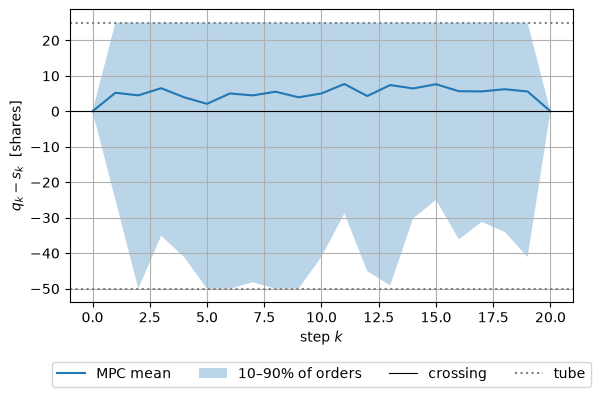

mean deviation, steps 1..N-1: 5.42 ± 0.66
share of steps at the lower edge (forced market orders): 0.088


≈ +25    0.553
≈ 0      0.217
≈ −25    0.128
≈ −50    0.103
Name: proportion, dtype: float64

In [9]:
dev = np.array([deviation(r) for r in res_m])                       # (orders, N+1)
assert dev.max() <= mpc_params.rho_up + 1 and dev.min() >= -mpc_params.rho_low - 1
lo, hi = np.percentile(dev, [10, 90], axis=0)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(k, dev.mean(0), label="MPC mean")
ax.fill_between(k, lo, hi, alpha=0.3, label="10–90% of orders")
ax.axhline(0, color="k", lw=0.8, label="crossing")
ax.set(xlabel=r"step $k$", ylabel=r"$q_k − s_k$  [shares]")
ax.grid()
for i, y in enumerate((mpc_params.rho_up, -mpc_params.rho_low)):
    ax.axhline(y, color="grey", ls=":", label="tube" if i == 0 else None)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4)

fig.savefig(FIG / "04_deviation_path.png", dpi=150, bbox_inches="tight")
plt.show()
d = pd.Series(dev[:, 1:-1].ravel())
state = pd.cut(d, [-51, -37.5, -12.5, 12.5, 26], labels=["≈ −50", "≈ −25", "≈ 0", "≈ +25"])
print("mean deviation, steps 1..N-1:", d.mean().round(2), "±", (dev[:, 1:-1].mean(1).std() / np.sqrt(len(dev))).round(2))
print("share of steps at the lower edge (forced market orders):", (d <= -mpc_params.rho_low + 1).mean().round(3))
state.value_counts(normalize=True).sort_index(ascending=False).round(3)

**Result.**
- The deviation never leaves the tube, and it lives on four values: one slice ahead 55% of the time, on schedule 22%,
  one slice behind 13%, two slices behind 10%. After a fill the order jumps to the upper edge, because it had posted
  exactly gap + `rho_up` and fills are all-or-nothing; each miss moves it down one slice.
- The mean is +5.4 ± 0.7 shares: MPC runs slightly *ahead* of its schedule, the opposite of the underfill reported in
  the paper. This comes from the settings, not from the fill model: with the tube binding, the policy posts as much as
  it is allowed to (section 5 shows the mean going below zero when the penalty takes over).

**Fill probability inside the loop.** The QP assumes 0.606 for every share posted at the touch. What does it obtain?
For every step with a limit order we compare the shares posted with the shares executed passively, grouped by the
size posted: 25 when the order is one slice ahead (the previous step filled), 50 after one miss, 75 after two or more.

In [10]:
f_tr = Factory(lambda: Traced(MPC(fill, mpc_params)))
res_t, _ = run(f_tr)
rows = []
for tr, r in zip(f_tr.made, res_t):
    filled = np.diff(r.filled_path)
    for step, (q, target, spread, orders) in enumerate(tr.log):
        mkt = sum(n for kind, n, _ in orders if kind == "market")
        lim = sum(n for kind, n, _ in orders if kind == "limit")
        if lim > 0:
            rows.append({"posted": lim, "frac": (filled[step] - mkt) / lim})
cal = pd.DataFrame(rows) # calibration
print("assumed:", fill.pi[0].round(3), " realised:", cal.frac.mean().round(3))
cal["size"] = pd.cut(cal.posted, [0, 37, 62, 100], labels=["≈25", "≈50", "≈75"])
cal.groupby("size", observed=True).frac.agg(["mean", "sem", "count"]).round(3)

assumed: 0.606  realised: 0.575


,mean,sem,count
size,,,
≈25,0.644,0.010,1984
≈50,0.535,0.015,990
≈75,0.456,0.016,826


**Result.** Assumed 0.606, obtained 0.575. The average hides two opposite errors:
- 25 shares posted (the previous step filled): 0.644 ± 0.010. The model is pessimistic.
- 50 shares (one miss): 0.535 ± 0.015.
- 75 shares (two or more misses): 0.456 ± 0.016. The model is optimistic by a third.

Order size alone does not explain a drop of 0.2 (notebook 03: at most 0.06 between 10 and 50 shares). The likelier
cause is the book: a fill means the queue ahead was short and a miss means it was long, and a queue takes about one
step to renew. The policy's own recent history carries information about the fill probability, and a constant pi
ignores it: it relies most on passive orders exactly when it is falling behind.

### 4. Cost against schedule deviation

The tubes set how much delay is tolerated before paying the spread (`rho_low`) and how far ahead of the schedule
the order may post (`rho_up`). Each configuration is a point in the (deviation, cost) plane; crossing is the point at
zero deviation.

In [11]:
%%time
rows = []
for rho_low in (25, 50, 100):  # 9 configs, 100 orders each: might take a few minutes to run
    for rho_up in (0, 25, 50):
        p = MPCParams(rho_low=rho_low, rho_up=rho_up)
        f = Factory(lambda p=p: MPC(fill, p))
        _, d = run(f, n_orders=100)
        rows.append({"rho_low": rho_low, "rho_up": rho_up,
                     "shortfall": d.schedule_shortfall_bps.mean(), "se": d.schedule_shortfall_bps.sem(),
                     "arrival": d.arrival_slippage_bps.mean(), "rms_dev": d.rms_deviation.mean(),
                     "passive": d.passive_share.mean(), "fallbacks": sum(x.n_fallbacks for x in f.made)})
front = pd.DataFrame(rows).round(3)
front

CPU times: user 2min 38s, sys: 982 ms, total: 2min 39s
Wall time: 2min 39s


,rho_low,rho_up,shortfall,se,arrival,rms_dev,passive,fallbacks
0,25,0,0.095,0.023,0.550,15.370,0.568,0
1,25,25,-0.102,0.028,0.552,21.727,0.767,0
2,25,50,-0.198,0.032,0.382,30.324,0.814,0
3,50,0,-0.030,0.036,0.664,23.580,0.752,0
4,50,25,-0.171,0.028,0.449,25.544,0.864,0
5,50,50,-0.242,0.033,0.165,32.879,0.890,0
6,100,0,-0.049,0.050,0.547,32.925,0.846,0
7,100,25,-0.131,0.046,0.624,32.031,0.903,0
8,100,50,-0.260,0.040,0.447,36.854,0.928,0


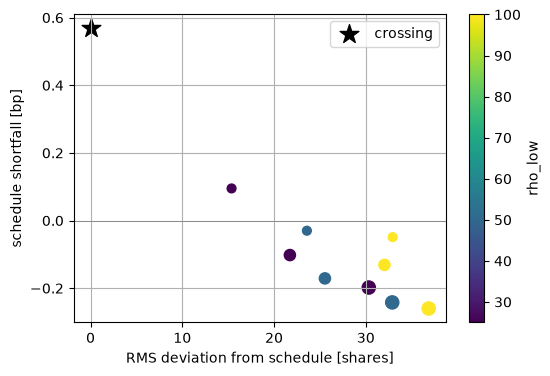

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
sc = ax.scatter(front.rms_dev, front.shortfall, c=front.rho_low, s=40 + front.rho_up)
ax.scatter(0, df_x.schedule_shortfall_bps.mean(), marker="*", s=200, color="k", label="crossing")
ax.axhline(0, color="grey", lw=0.5)
ax.set(xlabel="RMS deviation from schedule [shares]", ylabel="schedule shortfall [bp]")
fig.colorbar(sc, label="rho_low")
ax.grid()
ax.legend()
fig.savefig(FIG / "04_cost_vs_deviation.png", dpi=150, bbox_inches="tight")
plt.show()

**Result** (100 orders per point; standard errors 0.02–0.05 bp).
- Every MPC configuration beats crossing (+0.57) by 0.5–0.8 bp. The first 15 shares of tolerated deviation are worth
  0.47 bp; going from 15 to 33 adds 0.34.
- `rho_up` is the lever: at any `rho_low`, going from 0 to 50 lowers the shortfall by 0.2–0.3 bp. Being allowed to
  post ahead of the schedule is what turns market orders into passive fills.
- `rho_low` helps a little from 25 to 50 (0.04–0.12 bp) and not beyond: at 100 the passive share keeps rising
  (0.86 → 0.90 at `rho_up` = 25) but the cost does not fall. Since spread capture follows the passive share, the extra
  spread earned is being returned as timing cost.
- The arrival column is too noisy at 100 orders to rank configurations.

### 5. When does the quadratic penalty matter?

In the trace of section 1 the total sent always equals gap + `rho_up`: the tube binds and `gamma` plays no role.
Without the tube the QP would post $(g + 1/2\gamma)/\pi_0$ at the touch, about 83 shares for a gap of 25 at
`gamma` = 0.02, against a cap of 50. The penalty becomes the binding force only when $1/2\gamma < 5$, i.e.
`gamma` > 0.1. Expectation: 0.02 and 0.1 give nearly the same results; at 0.5 the policy posts less, aims at the
schedule in expectation, and the mean deviation moves towards zero at some cost in shortfall.

In [13]:
%%time
rows_g = []
for gamma in (0.02, 0.1, 0.5):          # default tubes; 100 orders each
    p = MPCParams(gamma=gamma)
    f = Factory(lambda p=p: MPC(fill, p))
    res, d = run(f, n_orders=100)
    dv = np.array([deviation(r) for r in res])[:, 1:-1]
    rows_g.append({"gamma": gamma, "shortfall": d.schedule_shortfall_bps.mean(), "se": d.schedule_shortfall_bps.sem(),
                   "mean_dev": dv.mean(), "rms_dev": d.rms_deviation.mean(), "passive": d.passive_share.mean(),
                   "fallbacks": sum(x.n_fallbacks for x in f.made)})
sweep = pd.DataFrame(rows_g).round(3)
sweep

CPU times: user 55.1 s, sys: 299 ms, total: 55.4 s
Wall time: 55.6 s


,gamma,shortfall,se,mean_dev,rms_dev,passive,fallbacks
0,0.02,-0.171,0.028,5.306,25.544,0.864,0
1,0.10,-0.180,0.028,-1.121,24.009,0.835,0
2,0.50,-0.122,0.024,-2.484,22.426,0.775,0


**Result.**
- `gamma` 0.02 → 0.1 → 0.5: mean deviation +5.3 → −1.1 → −2.5 shares; shortfall −0.17 → −0.18 → −0.12 bp
  (se 0.03 each); passive share 0.86 → 0.84 → 0.78.
- At 0.1 the order is centred on its schedule at no measurable cost: the policy stops posting ahead, executes fewer
  shares passively and loses nothing. At 0.5 it starts to pay, about 0.05 bp.
- The expectation was half right: between 0.02 and 0.1 the cost does not change, but the mean deviation does.
- The spread of the deviation barely moves (RMS 25.5 → 22.4 shares). It comes from all-or-nothing fills of
  slice-sized orders, which no value of `gamma` can smooth.

## Conclusions

200 orders of 500 shares, same seeds as the crossing baseline:

| | crossing | MPC, constant pi |
|---|---|---|
| schedule shortfall | +0.57 bp | −0.19 bp |
| arrival slippage | +1.00 bp | +0.45 bp |
| passive share | 0 | 87% |
| completion | 1 | 1 |
| RMS deviation from schedule | 0 | 26 shares (one slice) |

1. **MPC is paid to trade where crossing pays.** The shortfall improves by 0.75 ± 0.02 bp. The gain is measured
   precisely on the shortfall and only roughly on the arrival price (−0.55 ± 0.26).
2. **Half of the spread captured is returned as timing cost**: −0.38 bp of spread capture, +0.20 bp of adverse
   selection, in a simulator with no informed traders.
3. **At these settings the QP is a two-threshold rule**: post gap + `rho_up` at the touch, send to market what exceeds
   `rho_low`. The upper tube is the lever on cost; a lower tube beyond two slices buys nothing; the quadratic penalty
   matters only from `gamma` ≈ 0.1, where it centres the order on the schedule for free.
4. **No systematic underfill**: the order runs 5 shares ahead on average. The deviation is not a diffuse band but four
   states one slice apart, because fills are all-or-nothing.
5. **The constant pi is wrong in a predictable way**: assumed 0.61; obtained 0.64 after a fill, 0.54 after one miss,
   0.46 after two. The policy leans hardest on passive orders exactly when they are least likely to fill.

Next: notebook 05 replaces the constant with a model of pi given the queue ahead, and measures whether that reduces
the steps at the lower edge, the forced market orders and the timing cost.